Processing run 1
Processing run 2
Processing run 3
Processing run 4
Processing run 5
Processing run 6
Processing run 7
Processing run 8
Processing run 9
Processing run 10
Processing run 11
Processing run 12
Processing run 13
Processing run 14
Processing run 15
Processing run 16
Processing run 17
Processing run 18
Processing run 19
Processing run 20
done
Consistent True Positives across runs: 18
Consistent True Positive Edges: {('G29', 'G30'), ('G90', 'G91'), ('G54', 'G99'), ('G38', 'G40'), ('G54', 'G87'), ('G12', 'G26'), ('G6', 'G89'), ('G12', 'G64'), ('G38', 'G41'), ('G33', 'G37'), ('G32', 'G54'), ('G32', 'G53'), ('G53', 'G68'), ('G1', 'G4'), ('G29', 'G32'), ('G54', 'G86'), ('G40', 'G62'), ('G53', 'G67')}
Consistent False Positives across runs: 21
Consistent False Positive Edges: {('G37', 'G88'), ('G40', 'G41'), ('G19', 'G68'), ('G29', 'G54'), ('G33', 'G68'), ('G100', 'G99'), ('G53', 'G54'), ('G12', 'G67'), ('G19', 'G32'), ('G86', 'G87'), ('G36', 'G88'), ('G33', 'G54'), ('G87', 'G99')

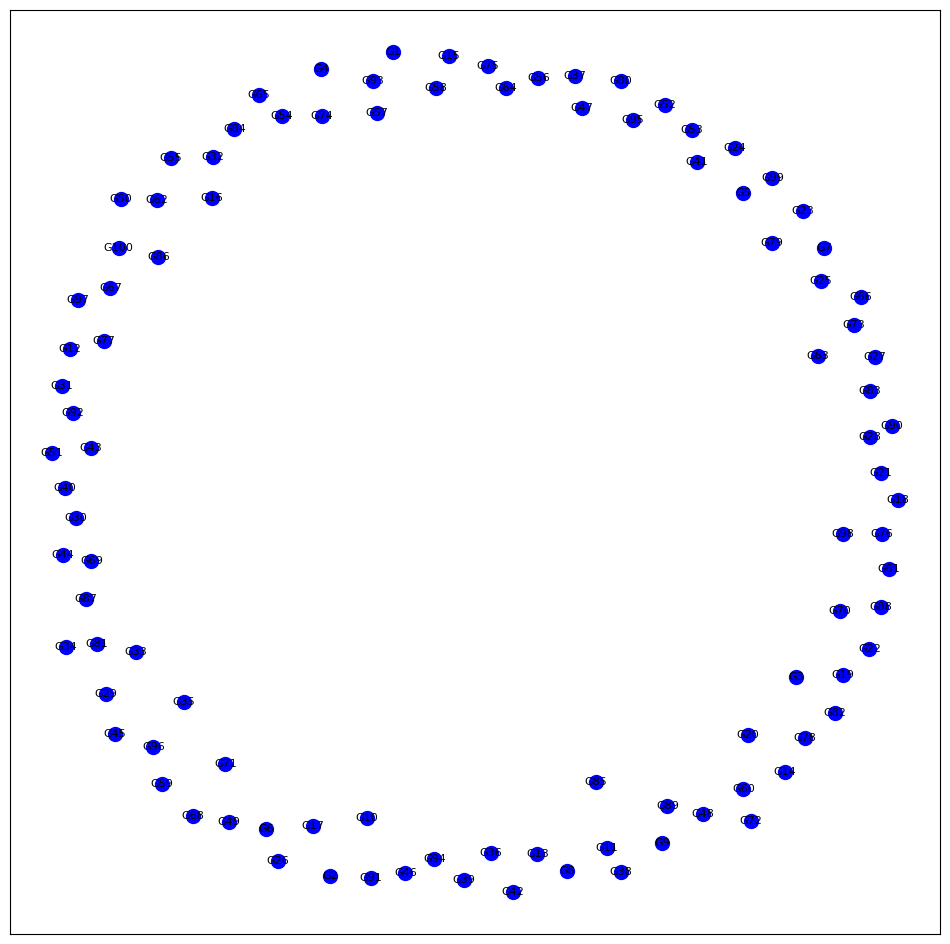

In [41]:
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, GAE
from torch_geometric.utils import from_scipy_sparse_matrix
from torch_geometric.data import Data
import scipy.sparse as sp
import pandas as pd
import networkx as nx
import networkx as nx
import matplotlib.pyplot as plt

# Load the data
data = pd.read_csv("/Users/nirwantandukar/input_data/Database.DREAM4/NORMALIZED_EXP/normalized_weight_matrix_all_GRN_100_03_0.1filter.csv", index_col=0)

# Get the list of algorithms
columns = data.columns
algorithms = sorted(set(col.split('.')[0] for col in columns))

num_genes = data.shape[0]
gene_names = data.index.tolist()

#node_features
# Node features (identity matrix)
node_features = np.identity(num_genes)

import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from torch.nn import BatchNorm1d

class GCNEncoder(torch.nn.Module):
    def __init__(self, in_channels, out_channels, num_layers=3, dropout_rate=0.1):
        super(GCNEncoder, self).__init__()
        
        self.num_layers = num_layers
        self.dropout_rate = dropout_rate
        
        # First layer: input to 2x hidden size
        self.convs = torch.nn.ModuleList()
        self.convs.append(GCNConv(in_channels, 2 * out_channels, cached=False))
        
        # Add intermediate layers
        for _ in range(num_layers - 2):
            self.convs.append(GCNConv(2 * out_channels, 2 * out_channels, cached=False))
        
        # Final layer: hidden size to output size
        self.convs.append(GCNConv(2 * out_channels, out_channels, cached=False))
        
        # Batch normalization layers for each convolution layer
        self.bns = torch.nn.ModuleList([BatchNorm1d(2 * out_channels) for _ in range(num_layers - 1)])
        
        # Dropout rate
        self.dropout = torch.nn.Dropout(p=dropout_rate)
        
        # LeakyReLU instead of ReLU
        self.activation = torch.nn.LeakyReLU(negative_slope=0.05)
        #self.activation = torch.nn.ReLU()

    def forward(self, x, edge_index):
        # First layer (without batch normalization)
        x = self.convs[0](x, edge_index)
        x = self.activation(x)
        x = F.relu(x)
        
        # Intermediate layers with batch normalization and dropout
        for i in range(1, self.num_layers - 1):
            x_residual = x  # For residual connection
            x = self.convs[i](x, edge_index)
            x = self.bns[i-1](x)  # Apply batch normalization
            x = self.activation(x)
            x = self.dropout(x)
            
            
            # Add residual connection (skip connection)
            x = x + x_residual
        
        # Final layer (no activation or batch norm)
        x = self.convs[-1](x, edge_index)
        x = F.relu(x)
        return x

# Normalize the adjacency matrix
def normalize_adj(adj):
    """Symmetrically normalize adjacency matrix."""
    adj = sp.coo_matrix(adj)
    rowsum = np.array(adj.sum(1)).flatten()
    d_inv_sqrt = np.power(rowsum + 1e-5, -0.5)
    d_inv_sqrt[np.isinf(d_inv_sqrt)] = 0.0
    d_mat_inv_sqrt = sp.diags(d_inv_sqrt)
    return adj.dot(d_mat_inv_sqrt).transpose().dot(d_mat_inv_sqrt).tocoo()

# GAE model with weight decay and dropout
def apply_gae_to_adjacency(adj_matrix, node_features, embedding_dim=16, epochs=200, dropout_rate=0.1, weight_decay=1e-4):
    # Convert adjacency matrix to sparse format
    adj_sparse = sp.csr_matrix(adj_matrix)
    # Normalize the adjacency matrix
    adj_normalized = normalize_adj(adj_sparse + sp.eye(adj_sparse.shape[0]))
    # Get edge_index and edge_weight
    edge_index, edge_weight = from_scipy_sparse_matrix(adj_normalized)
    # Create data object
    x = torch.tensor(node_features, dtype=torch.float)
    data = Data(x=x, edge_index=edge_index)
    # Define model
    model = GAE(GCNEncoder(x.shape[1], embedding_dim, dropout_rate=dropout_rate))
    # Training settings
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    data = data.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.05, weight_decay=weight_decay)  # Applying weight decay
    # Training loop
    model.train()
    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()
        z = model.encode(data.x, data.edge_index)
        loss = model.recon_loss(z, data.edge_index)
        loss.backward()
        optimizer.step()
    # After training, reconstruct adjacency matrix
    model.eval()
    with torch.no_grad():
        z = model.encode(data.x, data.edge_index)
        adj_reconstructed = model.decoder.forward_all(z).cpu().numpy()
    return adj_reconstructed

# Create the graph from the adjacency matrix
G = nx.from_pandas_adjacency(adj_df)
# Remove self-loops
G.remove_edges_from(nx.selfloop_edges(G))
# Draw the graph
plt.figure(figsize=(12, 12))
pos = nx.spring_layout(G, k=0.15)  # You can adjust 'k' for spacing
nx.draw_networkx_nodes(G, pos, node_size=100, node_color='blue')
nx.draw_networkx_edges(G, pos, alpha=0.3)
nx.draw_networkx_labels(G, pos, font_size=8)
#plt.axis('off')
#plt.title('Gene Interaction Network')
#plt.show()

# Step 1: Load known (ground truth) interactions
file_path = "/Users/nirwantandukar/input_data/Database.DREAM4/GS/dream4_100_03_gs.csv"

ground_truth = pd.read_csv(file_path, index_col=0)

# Convert ground truth matrix to edge list
def convert_matrix_to_edge_list(matrix):
    edges = []
    for source in matrix.index:
        for target in matrix.columns:
            if matrix.at[source, target] == 1:
                edges.append((source, target))
    return edges

# Get the ground truth edges
known_edges = convert_matrix_to_edge_list(ground_truth)

# Step 2: Get the predicted edges from the GRN (from your constructed GRN)
# Assume GRN is stored in a NetworkX graph `predicted_grn`
predicted_grn=G
# Convert predicted GRN to edge list
predicted_edges = list(predicted_grn.edges())

# Step 3: Compare the predicted and ground truth edges

# Convert edges to sets for easy comparison
known_edges_set = set(known_edges)
predicted_edges_set = set(predicted_edges)

# True Positives (correct predictions)
true_positives = predicted_edges_set.intersection(known_edges_set)

# False Positives (predicted edges that are not in the ground truth)
false_positives = predicted_edges_set.difference(known_edges_set)

# False Negatives (ground truth edges that are missing in the predictions)
false_negatives = known_edges_set.difference(predicted_edges_set)

# Step 4: Output the results
#print(f"Number of True Positives (Correct edges): {len(true_positives)}")
#print(f"Number of False Positives (Wrong edges): {len(false_positives)}")
#print(f"Number of False Negatives (Missing edges): {len(false_negatives)}")

# Optional: print out the edges for further analysis
#print(f"\nTrue Positive Edges:\n{true_positives}")
#print(f"\nFalse Positive Edges:\n{false_positives}")
#print(f"\nFalse Negative Edges:\n{false_negatives}")


import numpy as np
import pandas as pd
import networkx as nx

# Define number of iterations
num_iterations = 20
run_threshold = 14  # Number of times an edge must appear to be considered "consistent"

# Store results from multiple runs
true_positive_runs = []
false_positive_runs = []

for run in range(num_iterations):
    print(f"Processing run {run + 1}")
    
    reconstructed_adjs = []

    for alg in algorithms:
        #print(f"Processing algorithm: {alg}")
        # Extract adjacency matrix for the algorithm
        alg_columns = [col for col in data.columns if col.startswith(alg + '.')]
        alg_matrix = data[alg_columns].values
        
        # Apply GAE
        adj_reconstructed = apply_gae_to_adjacency(alg_matrix, node_features)
        
        # Binarize the reconstructed adjacency matrix
        individual_threshold = 0.6  # Adjust based on your data
        adj_binary = (adj_reconstructed > individual_threshold).astype(int)
        reconstructed_adjs.append(adj_binary)
    
    # Sum the binary adjacency matrices across algorithms
    aggregated_adj = np.sum(reconstructed_adjs, axis=0)
    adj_binary = (aggregated_adj >= 8).astype(int)
    
    # Create graph from the reconstructed adjacency matrix for this run
    adj_df = pd.DataFrame(adj_binary, index=gene_names, columns=gene_names)
    G_run = nx.from_pandas_adjacency(adj_df)
    G_run.remove_edges_from(nx.selfloop_edges(G_run))
    
    # Get the predicted edges
    predicted_edges_run = set(G_run.edges())
    
    # Get the ground truth edges
    known_edges_set = set(convert_matrix_to_edge_list(ground_truth))
    
    # Calculate true positives for this run
    true_positives_run = predicted_edges_run.intersection(known_edges_set)
    
    # Calculate false positives for this run
    false_positives_run = predicted_edges_run.difference(known_edges_set)
    
    # Store the true positives for this run
    true_positive_runs.append(true_positives_run)
    false_positive_runs.append(false_positives_run)

# Find edges that appear consistently across runs
edge_counts = {}
for edges in true_positive_runs:
    for edge in edges:
        if edge in edge_counts:
            edge_counts[edge] += 1
        else:
            edge_counts[edge] = 1

# Select edges that appear in at least the run_threshold times
consistent_edges = {edge for edge, count in edge_counts.items() if count >= run_threshold}

# Consistent False Positives across all runs
consistent_false_positives = set.intersection(*false_positive_runs)

print(f"done")
# Output the final set of consistent true positives
print(f"Consistent True Positives across runs: {len(consistent_edges)}")
print(f"Consistent True Positive Edges: {consistent_edges}")

# Consistent False Negatives across all runs
print(f"Consistent False Positives across runs: {len(consistent_false_positives)}")
print(f"Consistent False Positive Edges: {consistent_false_positives}")


In [39]:
10 and 8
Consistent True Positives across runs: 19
Consistent True Positive Edges: {('G53', 'G68'), ('G40', 'G62'), ('G55', 'G56'), ('G33', 'G36'), ('G34', 'G56'), ('G34', 'G55'), ('G6', 'G89'), ('G32', 'G54'), ('G29', 'G32'), ('G29', 'G30'), ('G39', 'G46'), ('G32', 'G53'), ('G90', 'G91'), ('G33', 'G37'), ('G12', 'G26'), ('G26', 'G28'), ('G54', 'G86'), ('G24', 'G25'), ('G38', 'G40')}
Consistent False Positives across runs: 36

array([[0.7349676, 0.6327793, 0.5835694, ..., 0.8344581, 0.7035331,
        0.5855411],
       [0.0485149, 0.0937415, 0.0691611, ..., 0.0945149, 0.0523277,
        0.0877537],
       [0.4524714, 0.1171985, 0.1722626, ..., 0.4314366, 0.3472774,
        0.4239015],
       ...,
       [0.6982051, 0.7656222, 0.6704368, ..., 0.5831992, 0.7059658,
        0.7228316],
       [0.7093223, 0.605458 , 0.757195 , ..., 0.6122191, 0.7341137,
        0.5535056],
       [0.6611915, 0.6818511, 0.6029798, ..., 0.6915877, 0.7633052,
        0.6724878]])

In [101]:
20 and 15 
Consistent True Positives across runs: 20
Consistent True Positive Edges: {('G53', 'G68'), ('G40', 'G62'), ('G55', 'G56'), ('G33', 'G36'), ('G34', 'G56'), ('G34', 'G55'), ('G6', 'G89'), ('G32', 'G54'), ('G29', 'G32'), ('G29', 'G30'), ('G39', 'G46'), ('G32', 'G53'), ('G90', 'G91'), ('G33', 'G37'), ('G12', 'G26'), ('G26', 'G28'), ('G54', 'G86'), ('G38', 'G40'), ('G24', 'G25'), ('G2', 'G43')}
Consistent False Positives across runs: 30

SyntaxError: invalid syntax (3633693381.py, line 1)

In [191]:
Old function
28 78
2 layers
New function
26 46
24 48
# 3 layers 0.6 - 14 
13 11
14 12

# 3 layers 0.8 - 14 - 0.5
9 and 6 
# 3 layers 0.8 - 14 - 0.1
14 and 16
12 and 10 

SyntaxError: invalid syntax (2098736329.py, line 1)

In [83]:

df

,perturbation.1.t0,perturbation.1.applied.t50,perturbation.1.applied.t100,perturbation.1.applied.t150,perturbation.1.applied.t200,perturbation.1.applied.t250,perturbation.1.applied.t300,perturbation.1.applied.t350,perturbation.1.applied.t400,perturbation.1.applied.t450,...,perturbation.10.removed.t550,perturbation.10.removed.t600,perturbation.10.removed.t650,perturbation.10.removed.t700,perturbation.10.removed.t750,perturbation.10.removed.t800,perturbation.10.removed.t850,perturbation.10.removed.t900,perturbation.10.removed.t950,perturbation.10.removed.t1000
G1,0.383547,0.337235,0.258846,0.303562,0.485542,0.385008,0.437654,0.611058,0.637294,0.545182,...,0.456472,0.494173,0.381909,0.488015,0.522844,0.383079,0.399251,0.341630,0.342299,0.424718
G2,0.009602,0.425519,0.555416,0.479384,0.492852,0.453490,0.473051,0.546858,0.593054,0.574786,...,0.013498,0.025165,0.021970,0.007660,0.015390,0.007574,0.007248,0.029006,0.009421,0.037771
G3,0.624389,0.559392,0.555237,0.672497,0.520241,0.720915,0.744254,0.743560,0.577549,0.671886,...,0.487605,0.645723,0.666022,0.652681,0.614945,0.715280,0.624701,0.674375,0.561782,0.594244
G4,0.266317,0.440976,0.653757,0.625354,0.618036,0.737137,0.667081,0.604785,0.601688,0.553009,...,0.406973,0.330567,0.356798,0.375950,0.382738,0.307552,0.282651,0.335346,0.430185,0.264345
G5,0.166950,0.146730,0.170644,0.178041,0.154644,0.205974,0.215060,0.187010,0.202623,0.098475,...,0.162294,0.169702,0.167535,0.138343,0.174245,0.128732,0.190376,0.172727,0.144401,0.202176
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
G96,0.614077,0.766901,0.691437,0.563653,0.727950,0.776565,0.578253,0.558208,0.552044,0.698143,...,0.656796,0.569111,0.605472,0.582503,0.561932,0.721862,0.659302,0.588001,0.720532,0.642923
G97,0.685972,0.704527,0.559441,0.673097,0.625469,0.716769,0.666868,0.630390,0.726956,0.599461,...,0.795209,0.726981,0.637896,0.765347,0.685988,0.747153,0.743305,0.586868,0.691282,0.664363
G98,0.078324,0.423123,0.638467,0.625216,0.557247,0.471640,0.632757,0.462209,0.510485,0.471295,...,0.057367,0.069816,0.099582,0.112111,0.048612,0.070544,0.045154,0.191169,0.188721,0.206138
G99,0.693478,0.634433,0.701524,0.771736,0.542411,0.625961,0.642441,0.615922,0.570325,0.716356,...,0.624255,0.674169,0.591432,0.599830,0.474222,0.681410,0.727430,0.559676,0.732399,0.705735


In [ ]:
class GCNEncoder(torch.nn.Module):
    def __init__(self, in_channels, out_channels, num_layers=2, dropout_rate=0.5):
        super(GCNEncoder, self).__init__()
        
        self.num_layers = num_layers
        self.dropout_rate = dropout_rate
        
        # First layer: input to 2x hidden size
        self.convs = torch.nn.ModuleList()
        self.convs.append(GCNConv(in_channels, 2 * out_channels, cached=False))
        
        # Add intermediate layers
        for _ in range(num_layers - 2):
            self.convs.append(GCNConv(2 * out_channels, 2 * out_channels, cached=False))
        
        # Final layer: hidden size to output size
        self.convs.append(GCNConv(2 * out_channels, out_channels, cached=False))
        
        # Batch normalization layers for each convolution layer
        self.bns = torch.nn.ModuleList([BatchNorm1d(2 * out_channels) for _ in range(num_layers - 1)])
        
        # Dropout rate
        self.dropout = torch.nn.Dropout(p=dropout_rate)
        
        # LeakyReLU instead of ReLU
        self.activation = torch.nn.LeakyReLU(negative_slope=0.05)
        #self.activation = torch.nn.ReLU()

    def forward(self, x, edge_index):
        # First layer (without batch normalization)
        x = self.convs[0](x, edge_index)
        x = self.activation(x)
        x = F.relu(x)
        
        # Intermediate layers with batch normalization and dropout
        for i in range(1, self.num_layers - 1):
            x_residual = x  # For residual connection
            x = self.convs[i](x, edge_index)
            x = self.bns[i-1](x)  # Apply batch normalization
            x = self.activation(x)
            x = self.dropout(x)
            
            
            # Add residual connection (skip connection)
            x = x + x_residual
        
        # Final layer (no activation or batch norm)
        x = self.convs[-1](x, edge_index)
        x = F.relu(x)
        return x

Processing run 1
Processing run 2
Processing run 3
Processing run 4
Processing run 5
Processing run 6
Processing run 7
Processing run 8
Processing run 9
Processing run 10
            Algorithm Raw_true_positive Raw_false_positive GCN_true_positive  \
0          GRN_ARACNE                NA                 NA                NA   
1          GRN_BC3NET                NA                 NA                NA   
2           GRN_C3NET                NA                 NA                NA   
3             GRN_CLR                NA                 NA                NA   
4       GRN_GENIE3_ET                NA                 NA                NA   
5       GRN_GENIE3_RF                NA                 NA                NA   
6         GRN_GRENIST                NA                 NA                NA   
7       GRN_GRNBOOST2                NA                 NA                NA   
8     GRN_INFERELATOR                NA                 NA                NA   
9          GRN_KBOOST        

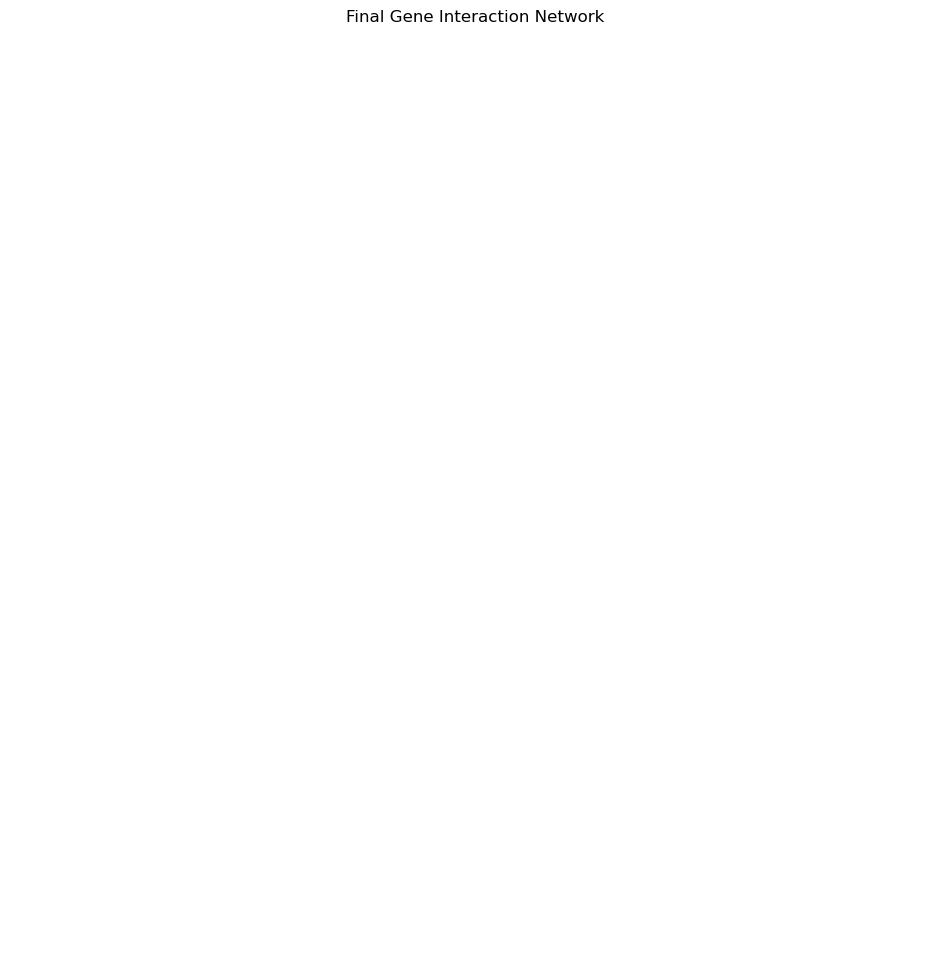

In [25]:
import pandas as pd
import numpy as np
import scipy.sparse as sp
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, GAE
from torch_geometric.utils import from_scipy_sparse_matrix
from torch_geometric.data import Data
import networkx as nx
import matplotlib.pyplot as plt

#import random
#random.seed(42)
#np.random.seed(42)
#torch.manual_seed(42)
#if torch.cuda.is_available():
#    torch.cuda.manual_seed_all(42)

# Load the data
data = pd.read_csv("/Users/nirwantandukar/input_data/Database.DREAM4/NORMALIZED_EXP/normalized_weight_matrix_all_GRN_100_03_0.1filter.csv", index_col=0)

# Get the list of algorithms
columns = data.columns
algorithms = sorted(set(col.split('.')[0] for col in columns))

num_genes = data.shape[0]
gene_names = data.index.tolist()

# Load known (ground truth) interactions
ground_truth = pd.read_csv("/Users/nirwantandukar/input_data/Database.DREAM4/GS/dream4_100_03_gs.csv", index_col=0)

# Function to convert a matrix to edge list
def convert_matrix_to_edge_list(matrix):
    edges = []
    for source in matrix.index:
        for target in matrix.columns:
            if matrix.at[source, target] == 1:
                edges.append((source, target))
    return edges

# Get the ground truth edges
known_edges_set = set(convert_matrix_to_edge_list(ground_truth))

# Define threshold for raw data
raw_data_threshold = 0.8  # You can adjust this threshold

# Initialize lists to store results
raw_results = []

for alg in algorithms:
    # Extract adjacency matrix for the algorithm
    alg_columns = [col for col in data.columns if col.startswith(alg + '.')]
    alg_matrix = data[alg_columns].values
    
    # Apply threshold
    adj_binary = (alg_matrix > raw_data_threshold).astype(int)
    
    # Create DataFrame for adjacency matrix
    adj_df = pd.DataFrame(adj_binary, index=gene_names, columns=gene_names)
    
    # Create graph from adjacency matrix
    G = nx.from_pandas_adjacency(adj_df)
    G.remove_edges_from(nx.selfloop_edges(G))
    
    # Get predicted edges
    predicted_edges_set = set(G.edges())
    
    # Calculate true positives and false positives
    true_positives = predicted_edges_set.intersection(known_edges_set)
    false_positives = predicted_edges_set.difference(known_edges_set)
    
    # Percentage of true positives
    percentage_true_positives = (len(true_positives) / len(known_edges_set)) * 100
    
    # Store results
    raw_results.append({
        'Algorithm': alg,
        'True Positives': len(true_positives),
        'False Positives': len(false_positives),
        'Percentage True Positives': percentage_true_positives
    })

class GCNEncoder(torch.nn.Module):
    def __init__(self, in_channels, out_channels, num_layers=3, dropout_rate=0.1):
        super(GCNEncoder, self).__init__()
        
        self.num_layers = num_layers
        self.dropout_rate = dropout_rate
        
        # First layer: input to 2x hidden size
        self.convs = torch.nn.ModuleList()
        self.convs.append(GCNConv(in_channels, 2 * out_channels, cached=False))
        
        # Add intermediate layers
        for _ in range(num_layers - 2):
            self.convs.append(GCNConv(2 * out_channels, 2 * out_channels, cached=False))
        
        # Final layer: hidden size to output size
        self.convs.append(GCNConv(2 * out_channels, out_channels, cached=False))
        
        # Batch normalization layers for each convolution layer
        self.bns = torch.nn.ModuleList([BatchNorm1d(2 * out_channels) for _ in range(num_layers - 1)])
        
        # Dropout rate
        self.dropout = torch.nn.Dropout(p=dropout_rate)
        
        # LeakyReLU instead of ReLU
        self.activation = torch.nn.LeakyReLU(negative_slope=0.05)
        #self.activation = torch.nn.ReLU()

    def forward(self, x, edge_index):
        # First layer (without batch normalization)
        x = self.convs[0](x, edge_index)
        x = self.activation(x)
        x = F.relu(x)
        
        # Intermediate layers with batch normalization and dropout
        for i in range(1, self.num_layers - 1):
            x_residual = x  # For residual connection
            x = self.convs[i](x, edge_index)
            x = self.bns[i-1](x)  # Apply batch normalization
            x = self.activation(x)
            x = self.dropout(x)
            
            
            # Add residual connection (skip connection)
            x = x + x_residual
        
        # Final layer (no activation or batch norm)
        x = self.convs[-1](x, edge_index)
        x = F.relu(x)
        return x

# Normalize the adjacency matrix
def normalize_adj(adj):
    """Symmetrically normalize adjacency matrix."""
    adj = sp.coo_matrix(adj)
    rowsum = np.array(adj.sum(1)).flatten()
    d_inv_sqrt = np.power(rowsum + 1e-5, -0.5)
    d_inv_sqrt[np.isinf(d_inv_sqrt)] = 0.0
    d_mat_inv_sqrt = sp.diags(d_inv_sqrt)
    return adj.dot(d_mat_inv_sqrt).transpose().dot(d_mat_inv_sqrt).tocoo()

# Apply GAE to adjacency matrix
def apply_gae_to_adjacency(adj_matrix, node_features, embedding_dim=16, epochs=200, dropout_rate=0.1, weight_decay=1e-4):
    # Convert adjacency matrix to sparse format
    adj_sparse = sp.csr_matrix(adj_matrix)
    # Normalize the adjacency matrix
    adj_normalized = normalize_adj(adj_sparse + sp.eye(adj_sparse.shape[0]))
    # Get edge_index and edge_weight
    edge_index, edge_weight = from_scipy_sparse_matrix(adj_normalized)
    # Create data object
    x = torch.tensor(node_features, dtype=torch.float)
    data = Data(x=x, edge_index=edge_index)
    # Define model
    model = GAE(GCNEncoder(x.shape[1], embedding_dim, dropout_rate=dropout_rate))
    # Training settings
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    data = data.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.05, weight_decay=weight_decay)  # Applying weight decay
    # Training loop
    model.train()
    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()
        z = model.encode(data.x, data.edge_index)
        loss = model.recon_loss(z, data.edge_index)
        loss.backward()
        optimizer.step()
    # After training, reconstruct adjacency matrix
    model.eval()
    with torch.no_grad():
        z = model.encode(data.x, data.edge_index)
        adj_reconstructed = model.decoder.forward_all(z).cpu().numpy()
    return adj_reconstructed

# Define node features (identity matrix)
node_features = np.identity(num_genes)

# Define number of iterations
num_iterations = 10

# Define threshold for GCN-modeled data
gcn_threshold = 0.8  # You can adjust this threshold

# Define aggregation threshold for combining algorithms
aggregation_threshold = 8  # Adjust based on number of algorithms

# Initialize list to store results
gcn_results = []

for run in range(num_iterations):
    print(f"Processing run {run + 1}")
    
    reconstructed_adjs = []

    for alg in algorithms:
        # Extract adjacency matrix for the algorithm
        alg_columns = [col for col in data.columns if col.startswith(alg + '.')]
        alg_matrix = data[alg_columns].values
        
        # Apply GAE
        adj_reconstructed = apply_gae_to_adjacency(alg_matrix, node_features)
        
        # Binarize the reconstructed adjacency matrix
        adj_binary = (adj_reconstructed > gcn_threshold).astype(int)
        reconstructed_adjs.append(adj_binary)
    
    # Sum the binary adjacency matrices across algorithms
    aggregated_adj = np.sum(reconstructed_adjs, axis=0)
    adj_binary = (aggregated_adj >= aggregation_threshold).astype(int)
    
    # Create DataFrame for adjacency matrix
    adj_df = pd.DataFrame(adj_binary, index=gene_names, columns=gene_names)
    
    # Create graph from adjacency matrix
    G_run = nx.from_pandas_adjacency(adj_df)
    G_run.remove_edges_from(nx.selfloop_edges(G_run))
    
    # Get predicted edges
    predicted_edges_set = set(G_run.edges())
    
    # Calculate true positives and false positives
    true_positives = predicted_edges_set.intersection(known_edges_set)
    false_positives = predicted_edges_set.difference(known_edges_set)
    
    # Percentage of true positives
    percentage_true_positives = (len(true_positives) / len(known_edges_set)) * 100
    
    # Store results
    gcn_results.append({
        'Run': run + 1,
        'True Positives': len(true_positives),
        'False Positives': len(false_positives),
        'Percentage True Positives': percentage_true_positives,
        'Predicted Edges': predicted_edges_set
    })

# Sum raw adjacency matrices across algorithms
raw_reconstructed_adjs = []

for alg in algorithms:
    # Extract adjacency matrix for the algorithm
    alg_columns = [col for col in data.columns if col.startswith(alg + '.')]
    alg_matrix = data[alg_columns].values
    
    # Apply threshold
    adj_binary = (alg_matrix > raw_data_threshold).astype(int)
    raw_reconstructed_adjs.append(adj_binary)

# Sum the binary adjacency matrices
raw_aggregated_adj = np.sum(raw_reconstructed_adjs, axis=0)

# Apply aggregation threshold
raw_adj_binary = (raw_aggregated_adj >= aggregation_threshold).astype(int)

# Create DataFrame for adjacency matrix
raw_adj_df = pd.DataFrame(raw_adj_binary, index=gene_names, columns=gene_names)

# Create graph from adjacency matrix
G_raw_combined = nx.from_pandas_adjacency(raw_adj_df)
G_raw_combined.remove_edges_from(nx.selfloop_edges(G_raw_combined))

# Get predicted edges
predicted_edges_raw_combined = set(G_raw_combined.edges())

# Calculate true positives and false positives
true_positives_raw_combined = predicted_edges_raw_combined.intersection(known_edges_set)
false_positives_raw_combined = predicted_edges_raw_combined.difference(known_edges_set)

# Percentage of true positives
percentage_true_positives_raw_combined = (len(true_positives_raw_combined) / len(known_edges_set)) * 100

# Store results
raw_combined_results = {
    'Algorithm': 'Combined Raw',
    'True Positives': len(true_positives_raw_combined),
    'False Positives': len(false_positives_raw_combined),
    'Percentage True Positives': percentage_true_positives_raw_combined
}

# Initialize counts
total_true_positives = 0
total_false_positives = 0

# Collect all predicted edges across runs
all_predicted_edges = []

for result in gcn_results:
    total_true_positives += result['True Positives']
    total_false_positives += result['False Positives']
    all_predicted_edges.append(result['Predicted Edges'])

# Aggregate predicted edges across runs
edge_counts = {}
for edges in all_predicted_edges:
    for edge in edges:
        if edge in edge_counts:
            edge_counts[edge] += 1
        else:
            edge_counts[edge] = 1

# Select edges that appear in at least run_threshold times
run_threshold = 16  # Number of times an edge must appear
consistent_edges = {edge for edge, count in edge_counts.items() if count >= run_threshold}

# Calculate true positives and false positives for consistent edges
consistent_true_positives = consistent_edges.intersection(known_edges_set)
consistent_false_positives = consistent_edges.difference(known_edges_set)

# Percentage of true positives
percentage_true_positives_consistent = (len(consistent_true_positives) / len(known_edges_set)) * 100

# Store results
gcn_combined_results = {
    'Algorithm': 'Combined GCN',
    'True Positives': len(consistent_true_positives),
    'False Positives': len(consistent_false_positives),
    'Percentage True Positives': percentage_true_positives_consistent
}

# Create DataFrame from raw results
raw_results_df = pd.DataFrame(raw_results)

# Create DataFrame from GCN results (averaged over runs)
gcn_results_df = pd.DataFrame(gcn_results)

# Average GCN results over runs
gcn_average_results = {
    'Algorithm': 'GCN Average',
    'True Positives': gcn_results_df['True Positives'].mean(),
    'False Positives': gcn_results_df['False Positives'].mean(),
    'Percentage True Positives': gcn_results_df['Percentage True Positives'].mean()
}

import pandas as pd

# Combine all the individual algorithm results
# For individual algorithms, GCN true positives/false positives will initially be NA
columns = [
    'Algorithm', 
    'Raw_true_positive', 'Raw_false_positive', 
    'GCN_true_positive', 'GCN_false_positive', 
    'Combined_raw_true', 'Combined_raw_false', 
    'Combined_GCN_true', 'Combined_GCN_false'
]

# Create a DataFrame for raw results
raw_results_df = pd.DataFrame(raw_results)

# Add combined results (for raw and GCN) to the table
combined_raw_results = {
    'Algorithm': 'Combined Raw',
    'Raw_true_positive': raw_combined_results['True Positives'],
    'Raw_false_positive': raw_combined_results['False Positives'],
    'Combined_raw_true': raw_combined_results['True Positives'],  # This is same as raw combined
    'Combined_raw_false': raw_combined_results['False Positives'],  # This is same as raw combined
}

gcn_combined_results = {
    'Algorithm': 'Combined GCN',
    'GCN_true_positive': gcn_combined_results['True Positives'],
    'GCN_false_positive': gcn_combined_results['False Positives'],
    'Combined_GCN_true': gcn_combined_results['True Positives'],
    'Combined_GCN_false': gcn_combined_results['False Positives']
}

# Now using pd.concat instead of .append
summary_df = pd.concat([raw_results_df, pd.DataFrame([combined_raw_results]), pd.DataFrame([gcn_combined_results])], ignore_index=True)

# Rearrange columns and fill NA for missing values
summary_df = summary_df.reindex(columns=columns).fillna('NA')

# Display the summary table
print(summary_df)


# Create graph from consistent edges
final_G = nx.Graph()
final_G.add_edges_from(consistent_edges)
final_G.remove_nodes_from(list(nx.isolates(final_G)))  # Remove unconnected nodes

# Draw the graph
plt.figure(figsize=(12, 12))
pos = nx.spring_layout(final_G, k=0.15)
nx.draw_networkx_nodes(final_G, pos, node_size=100, node_color='blue')
nx.draw_networkx_edges(final_G, pos, alpha=0.3)
nx.draw_networkx_labels(final_G, pos, font_size=8)
plt.axis('off')
plt.title('Final Gene Interaction Network')
plt.show()


In [13]:
gcn_average_results

{'Algorithm': 'GCN Average',
 'True Positives': 40.75,
 'False Positives': 372.05,
 'Percentage True Positives': 21.005154639175252}

In [27]:
gcn_results

[{'Run': 1,
  'True Positives': 42,
  'False Positives': 354,
  'Percentage True Positives': 21.649484536082475,
  'Predicted Edges': {('G1', 'G18'),
   ('G1', 'G20'),
   ('G1', 'G36'),
   ('G1', 'G38'),
   ('G1', 'G39'),
   ('G1', 'G4'),
   ('G1', 'G40'),
   ('G1', 'G41'),
   ('G1', 'G46'),
   ('G1', 'G6'),
   ('G1', 'G60'),
   ('G1', 'G62'),
   ('G1', 'G75'),
   ('G1', 'G77'),
   ('G1', 'G8'),
   ('G1', 'G90'),
   ('G1', 'G91'),
   ('G10', 'G100'),
   ('G10', 'G11'),
   ('G10', 'G12'),
   ('G10', 'G13'),
   ('G10', 'G32'),
   ('G10', 'G35'),
   ('G10', 'G54'),
   ('G10', 'G64'),
   ('G10', 'G67'),
   ('G10', 'G86'),
   ('G10', 'G87'),
   ('G10', 'G9'),
   ('G10', 'G99'),
   ('G100', 'G11'),
   ('G100', 'G12'),
   ('G100', 'G19'),
   ('G100', 'G26'),
   ('G100', 'G32'),
   ('G100', 'G33'),
   ('G100', 'G35'),
   ('G100', 'G48'),
   ('G100', 'G53'),
   ('G100', 'G54'),
   ('G100', 'G64'),
   ('G100', 'G67'),
   ('G100', 'G86'),
   ('G100', 'G87'),
   ('G100', 'G99'),
   ('G11', 'G12'),